# Model Selection: BIC, AIC, and ICL

This notebook demonstrates `tgmm.select_model`, the Phase 1 (v0.4 roadmap) model-selection
sweep, and `GaussianMixture.icl`, the Integrated Completed Likelihood (Biernacki, Celeux &
Govaert, 2000).

BIC and AIC score a fitted mixture purely on log-likelihood plus a complexity penalty -- they
don't care whether the mixture's components are cleanly separated or heavily overlapping, as
long as the extra components earn their keep in likelihood. ICL adds an entropy penalty for
*ambiguous* assignments (`-2 * sum_i log(responsibility of the point's most likely component)`),
so on data with overlapping clusters it tends to prefer **fewer, better-separated** components
than BIC does on the same data, even though both reduce to the same thing when clusters are
perfectly separated (one-hot responsibilities).


In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import os

os.chdir('../')

from tgmm import GaussianMixture, generate_gmm_data, select_model
from tgmm.plotting import CATEGORICAL_PALETTE

random_state = 42
np.random.seed(random_state)
torch.manual_seed(random_state)


## A dataset with overlapping blobs

Five true components in two dimensions: two pairs that overlap substantially (`(0, 0)`/`(2.2,
0)` and `(6, 6)`/`(8.2, 6)`), plus one isolated component (`(0, 2.2)`). Each pair is close enough
relative to its spread that a 2- or 3-component mixture can already explain most of the
likelihood in that region -- the point of this dataset is to make BIC and ICL disagree about
how many of the five "true" components are worth resolving separately.


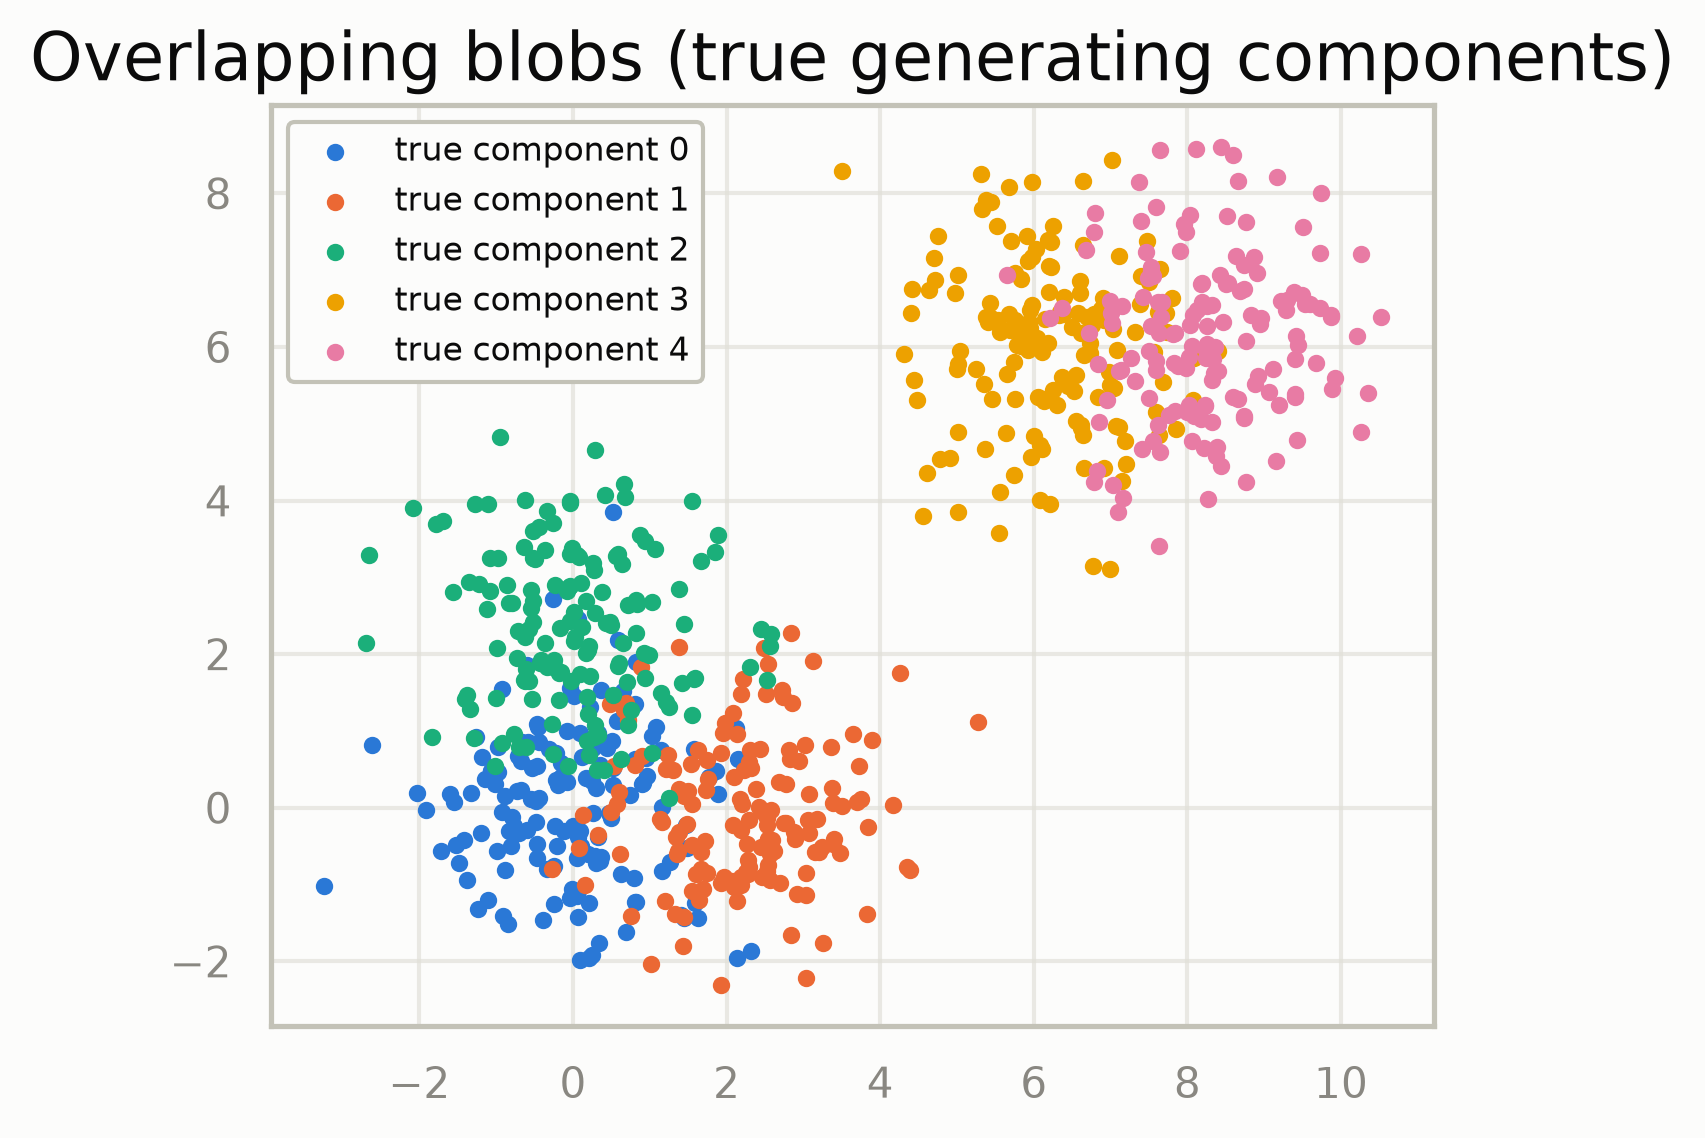

In [2]:
centers = [
    np.array([0.0, 0.0]),
    np.array([2.2, 0.0]),
    np.array([0.0, 2.2]),
    np.array([6.0, 6.0]),
    np.array([8.2, 6.0]),
]
covs = [np.eye(2) for _ in centers]
n_samples = [150] * len(centers)

X, true_labels = generate_gmm_data(centers, covs, n_samples, random_state=random_state)

plt.figure(figsize=(5, 5))
for k in range(len(centers)):
    mask = true_labels == k
    plt.scatter(X[mask, 0], X[mask, 1], s=10, color=CATEGORICAL_PALETTE[k % len(CATEGORICAL_PALETTE)],
                label=f'true component {k}')
plt.legend(fontsize=8)
plt.title('Overlapping blobs (true generating components)')
plt.gca().set_aspect('equal')
plt.show()


## Sweep `n_components` with `select_model`

`select_model` fits a `GaussianMixture` for every requested `n_components`, recording
`bic`, `aic`, `icl`, the final log-likelihood, and whether each fit converged.


In [3]:
result = select_model(
    X,
    n_components=range(1, 9),
    covariance_types=('full',),
    criterion='bic',
    n_init=3,
    random_state=0,
    max_iter=200,
)

for row in result.table:
    print(f"K={row['n_components']}  bic={row['bic']:.1f}  aic={row['aic']:.1f}  "
          f"icl={row['icl']:.1f}  icl-bic={row['icl'] - row['bic']:.1f}  converged={row['converged']}")


/home/asp/Downloads/HeaDS/tgmm/tgmm/gmm.py:1281: UserWarning: With n_init=3 and random_state=0, initializations will use random states [0, 1, ..., 2]. The best initialization's random state will be stored in best_random_state_.
  warnings.warn(


/home/asp/Downloads/HeaDS/tgmm/tgmm/gmm.py:1349: UserWarning: Best result from random_state=0. To reproduce this specific result: use random_state=0 with n_init=1.
  warnings.warn(


/home/asp/Downloads/HeaDS/tgmm/tgmm/gmm.py:1349: UserWarning: Best result from random_state=2. To reproduce this specific result: use random_state=2 with n_init=1.
  warnings.warn(


K=1  bic=7064.1  aic=7041.0  icl=7064.1  icl-bic=0.0  converged=True
K=2  bic=6213.2  aic=6162.4  icl=6213.3  icl-bic=0.1  converged=True
K=3  bic=6191.4  aic=6112.9  icl=6321.4  icl-bic=129.9  converged=True
K=4  bic=6209.7  aic=6103.5  icl=6358.6  icl-bic=148.9  converged=True
K=5  bic=6238.6  aic=6104.6  icl=6482.0  icl-bic=243.4  converged=True
K=6  bic=6273.1  aic=6111.4  icl=6584.2  icl-bic=311.1  converged=True
K=7  bic=6308.3  aic=6118.9  icl=6716.8  icl-bic=408.5  converged=True
K=8  bic=6338.4  aic=6121.2  icl=6748.4  icl-bic=410.0  converged=True


## BIC vs. ICL curves

Both criteria are "lower is better." Watch where each curve's minimum sits.


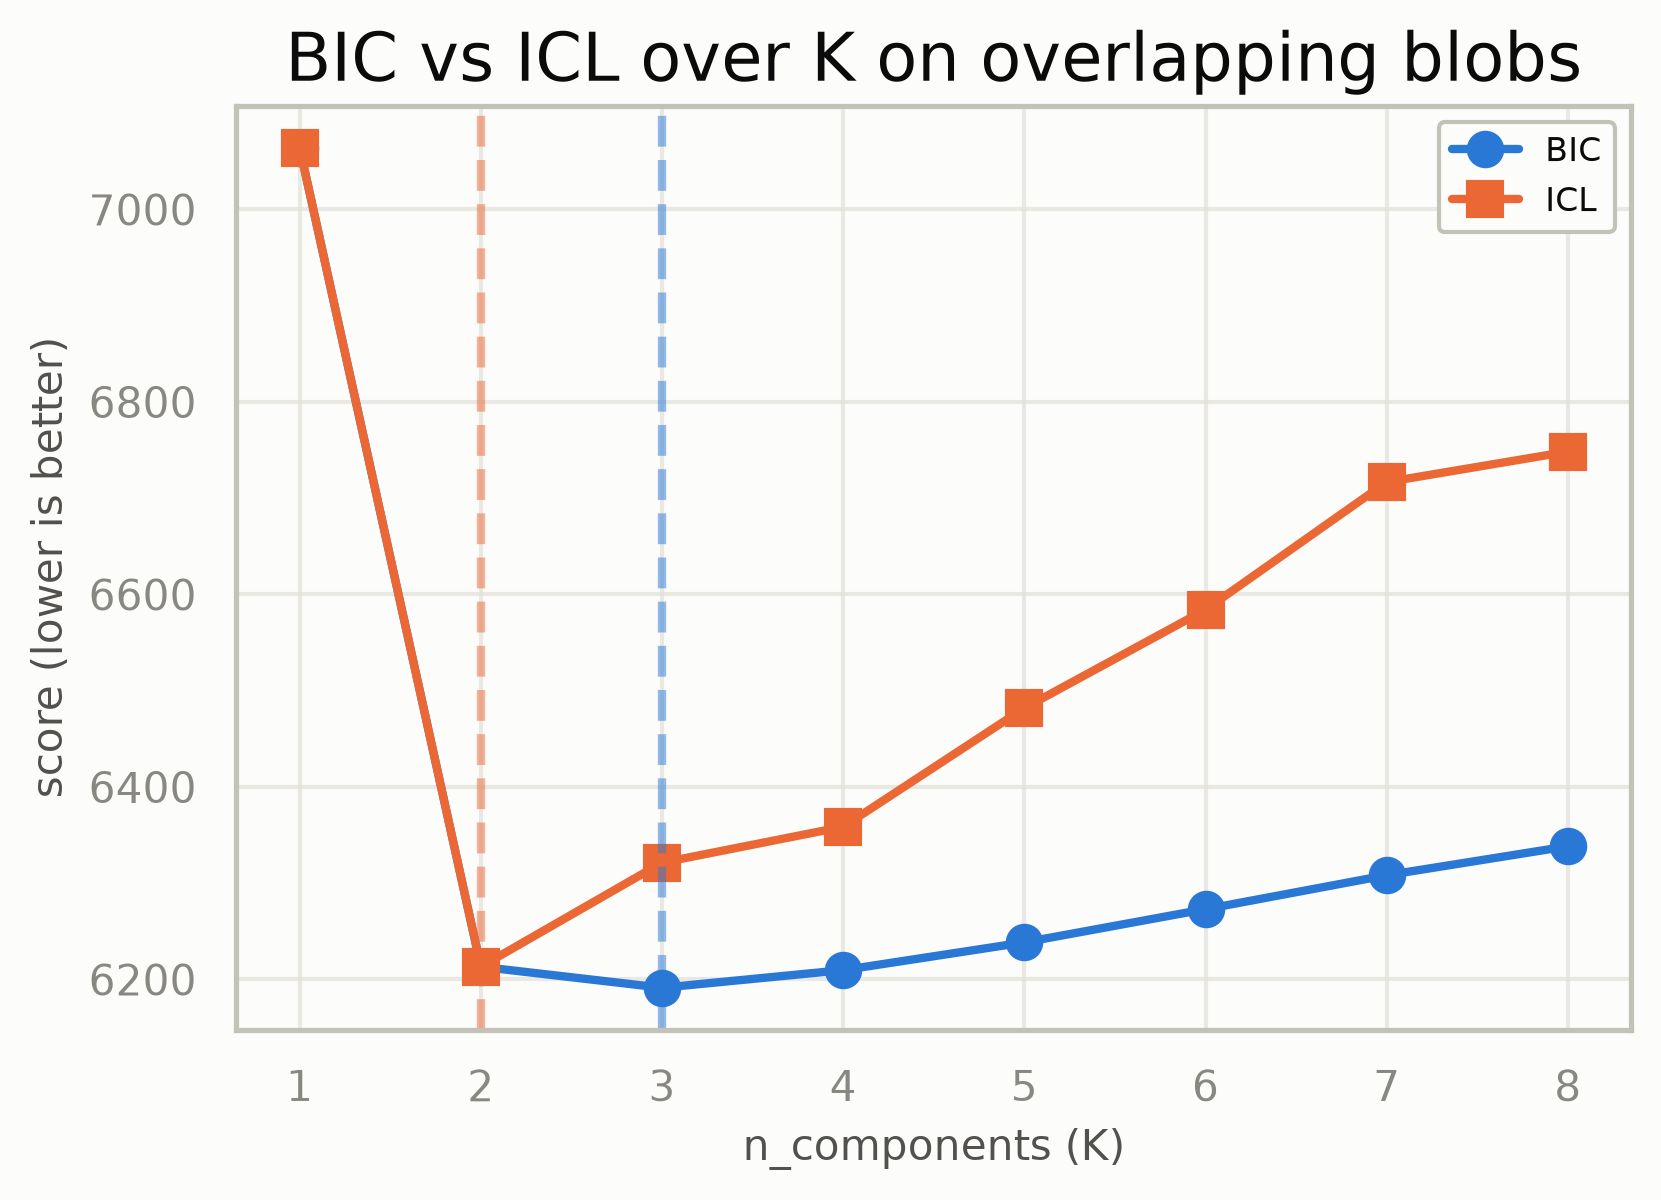

BIC-optimal K = 3
ICL-optimal K = 2


In [4]:
ks = [row['n_components'] for row in result.table]
bics = [row['bic'] for row in result.table]
icls = [row['icl'] for row in result.table]

best_bic_k = ks[int(np.argmin(bics))]
best_icl_k = ks[int(np.argmin(icls))]

plt.figure(figsize=(6, 4))
plt.plot(ks, bics, marker='o', label='BIC')
plt.plot(ks, icls, marker='s', label='ICL')
plt.axvline(best_bic_k, color='C0', linestyle='--', alpha=0.5)
plt.axvline(best_icl_k, color='C1', linestyle='--', alpha=0.5)
plt.xlabel('n_components (K)')
plt.ylabel('score (lower is better)')
plt.title('BIC vs ICL over K on overlapping blobs')
plt.legend()
plt.show()

print(f'BIC-optimal K = {best_bic_k}')
print(f'ICL-optimal K = {best_icl_k}')


As expected on this overlapping dataset, **ICL settles on fewer components than BIC**: BIC
keeps adding components as long as they buy a bit more likelihood, while ICL's entropy penalty
charges for the ambiguity introduced by splitting an overlapping pair into two components whose
responsibilities are never cleanly one-hot. Neither is "wrong" -- they answer different
questions (best density estimate vs. best *well-separated partition*).

`result.best_` is the fitted `GaussianMixture` that minimised the sweep's `criterion` (`'bic'`
here); `result.to_dataframe()` gives the same table as a `pandas.DataFrame` for further analysis.


In [5]:
print(type(result.best_))
print('best_ n_components:', result.best_.n_components)

df = result.to_dataframe()
df.head()


<class 'tgmm.gmm.GaussianMixture'>
best_ n_components: 3


,n_components,covariance_type,bic,aic,icl,log_likelihood,converged
0,1,full,7064.127206,7041.026840,7064.127206,-4.687351,True
1,2,full,6213.222645,6162.401840,6213.299130,-4.093601,True
2,3,full,6191.435383,6112.894138,6321.354420,-4.052596,True
3,4,full,6209.721753,6103.460070,6358.645643,-4.038307,True
4,5,full,6238.553139,6104.571016,6481.961251,-4.031047,True


## `icl()` on a single fitted model

`icl(X, mode='hard')` (the default) uses the most-likely component per point;
`mode='soft'` uses the full responsibility-entropy penalty instead. Both agree exactly with
`bic()` whenever responsibilities are one-hot (e.g. far-apart, well-separated components), and
diverge more the more overlapping/ambiguous the fit is -- which is exactly what drives the gap
in the curves above.


In [6]:
gmm = result.models_[(best_bic_k, 'full')]
print('bic:      ', gmm.bic(X))
print('icl hard: ', gmm.icl(X, mode='hard'))
print('icl soft: ', gmm.icl(X, mode='soft'))


bic:       6191.435382847198
icl hard:  6321.354419712432


icl soft:  6435.425464634307
